# **Library**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib import reload
from pathlib import Path
from modules import preprocess
from modules import calibration
import plotly.graph_objects as go

reload(preprocess)
reload(calibration)

# **Data**

### **Files Path**

In [2]:
current_dir_path, data_dir_path = preprocess.set_data_path('Data') # file path
atm_df_raw = preprocess.read_file(data_dir_path, 'ATM_IV.xlsx', pd.read_excel, sheet_name = 'ATMF') # dataset 1
smile_dec_df_raw = preprocess.read_file(data_dir_path, 'IV_Smile_Dec_2026.csv', pd.read_csv) # dataset 2 
smile_mar_df_raw = preprocess.read_file(data_dir_path, 'IV_Smile_Mar_2027.csv', pd.read_csv) # dataset 2

### **Forward Price**

In [3]:
T0 = pd.Timestamp('2026-10-12') # pricing date in year fraction
fwd_dec = atm_df_raw.loc[atm_df_raw['expiry'] == '2026-12-18']['fwd'].iloc[0] # forward Dec 2026
fwd_mar = atm_df_raw.loc[atm_df_raw['expiry'] == '2027-03-19']['fwd'].iloc[0] # foward Mar 2026 
fwd = [fwd_dec, fwd_mar]

### **Dataset Preparation**

In [4]:
smile_dec_df_raw['F'] = fwd_dec
smile_mar_df_raw['F'] = fwd_mar
smile_dec_df_raw['tau'] = (pd.Timestamp('2026-12-18') - T0).days / 365
smile_mar_df_raw['tau'] = (pd.Timestamp('2027-03-19') - T0).days / 365

In [5]:
calibration_df_2 = pd.concat(
    [smile_dec_df_raw, smile_mar_df_raw], ignore_index=True, axis=0)

In [6]:
calibration_df_2

,Strike,Mid_iv,Ask_iv,Bid_iv,iv_spread,type,F,tau
0,4800,0.471461,0.473311,0.469568,0.003742,put,7849.07,0.183562
1,4900,0.458680,0.460355,0.456969,0.003386,put,7849.07,0.183562
2,4975,0.449265,0.451584,0.446878,0.004707,put,7849.07,0.183562
3,5000,0.445567,0.447093,0.444012,0.003081,put,7849.07,0.183562
4,5100,0.433587,0.434960,0.432191,0.002768,put,7849.07,0.183562
...,...,...,...,...,...,...,...,...
189,8600,0.121058,0.121296,0.120819,0.000477,call,7927.95,0.432877
190,8650,0.120293,0.120508,0.120077,0.000432,call,7927.95,0.432877
191,8800,0.118454,0.118740,0.118168,0.000572,call,7927.95,0.432877
192,8900,0.117540,0.117824,0.117256,0.000568,call,7927.95,0.432877


In [7]:
atm_df_raw.head()
calibration_df_1 = atm_df_raw[['T', 'atmf_iv', 'atmf_var']]
calibration_df_1.head()

,T,atmf_iv,atmf_var
0,0.002740,0.093022,0.008653
1,0.005479,0.108673,0.011810
2,0.008219,0.107826,0.011626
3,0.010959,0.103406,0.010693
4,0.019178,0.093182,0.008683


# **Long Term Volatility**

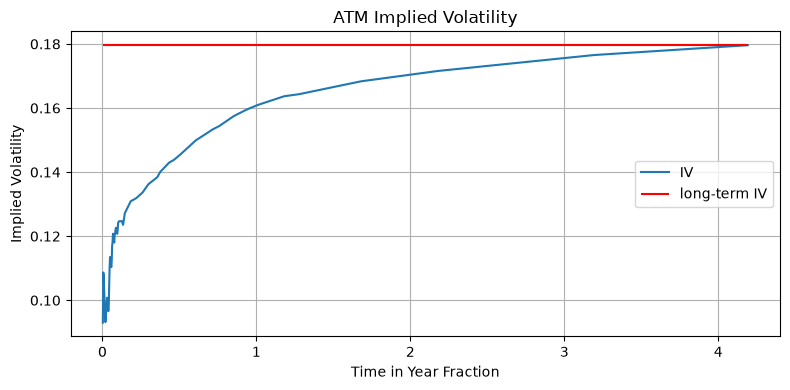

In [8]:
plt.figure(figsize=(8,4))

T_min = calibration_df_1['T'].min()
T_max = calibration_df_1['T'].max()
long_term_iv = calibration_df_1['atmf_iv'][calibration_df_1['T'] == T_max]

plt.plot(calibration_df_1['T'], calibration_df_1['atmf_iv'], label = 'IV')
plt.hlines(long_term_iv, T_min, T_max, colors='red', label = 'long-term IV')
plt.title('ATM Implied Volatility')
plt.xlabel('Time in Year Fraction')
plt.ylabel('Implied Volatility')
plt.legend(loc = 'right')
plt.grid(True)
plt.tight_layout()
display()

## **Third Fridays Each Month for tighter quote**

In [9]:
dataset1_expiries = pd.to_datetime([
    '2026-10-16', '2026-11-20', '2026-12-18',
    '2027-01-15', '2027-02-19', '2027-03-19', '2027-04-16', '2027-05-21', '2027-06-17',
    '2027-07-16', '2027-08-20', '2027-09-17', '2027-10-15', '2027-12-17',
    '2028-01-21', '2028-06-16', '2028-12-15', '2029-12-21', '2030-12-20'])

calibration_df_1 = atm_df_raw[atm_df_raw['expiry'].isin(dataset1_expiries)][['T', 'atmf_iv', 'atmf_var']]

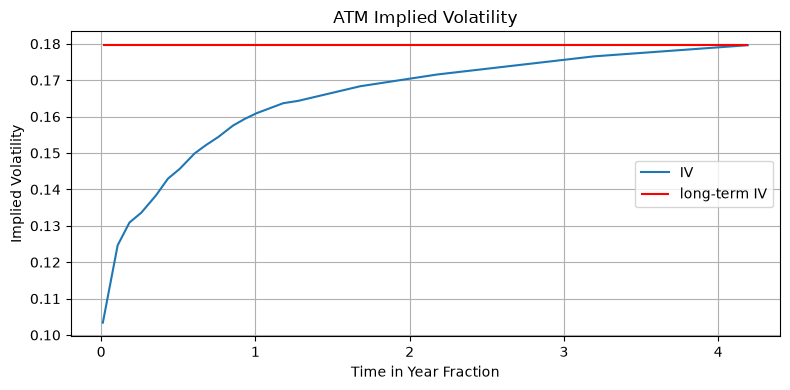

In [10]:
plt.figure(figsize=(8,4))

T_min = calibration_df_1['T'].min()
T_max = calibration_df_1['T'].max()
long_term_iv = calibration_df_1['atmf_iv'][calibration_df_1['T'] == T_max]

plt.plot(calibration_df_1['T'], calibration_df_1['atmf_iv'], label = 'IV')
plt.hlines(long_term_iv, T_min, T_max, colors='red', label = 'long-term IV')
plt.title('ATM Implied Volatility')
plt.xlabel('Time in Year Fraction')
plt.ylabel('Implied Volatility')
plt.legend(loc = 'right')
plt.grid(True)
plt.tight_layout()
display()

# **Step 1: Initial Guess for v_0, $\kappa$, and $\theta$**

In [11]:
v_0 = atm_df_raw.loc[atm_df_raw['expiry'] == '2026-10-16', 'atmf_var'].values[0]
theta_0 = calibration_df_1['atmf_var'][calibration_df_1['T'] == T_max].values[0]
kappa_0 = 1.5
print(f'Initial Guess: (v_0={v_0:.4f}, theta_0={theta_0:.4f}, kappa_0={kappa_0})')

Initial Guess: (v_0=0.0107, theta_0=0.0323, kappa_0=1.5)


In [12]:
T = calibration_df_1['T']
mrk_var = calibration_df_1['atmf_var']

In [13]:
kappa, theta = calibration.fit_kappa_theta(
    T, v_0, mrk_var, kappa_0, theta_0)

In [14]:
print(kappa, theta)

2.9091778609439176 0.03328079966493144


# **Step 2: Estimate $\rho$ and $\eta$**

## **Initial Parameters**

In [15]:
eta_0 = 1.0
rho_0 = -0.5
print(f'Initial Parameters:\nv_0 = {v_0:.6f}\ntheta = {theta:.6f}\nkappa = {kappa:6f}\neta = {eta_0}\nrho = {rho_0}')

Initial Parameters:
v_0 = 0.010693
theta = 0.033281
kappa = 2.909178
eta = 1.0
rho = -0.5


In [16]:
F = calibration_df_2['F'].values
K = calibration_df_2['Strike'].values
tau = calibration_df_2['tau'].values
option = calibration_df_2['type'].values
mid_iv = calibration_df_2['Mid_iv'].values
iv_spread = calibration_df_2['iv_spread'].values
params = [eta_0, rho_0]

## **Regular Fit**

In [17]:
eta, rho, sse = calibration.fit_eta_rho(
    params, F, K, tau,
    v_0, kappa, theta, option, mid_iv)

In [18]:
heston_params = [v_0, theta, kappa, eta, rho]

print(f'eta:{eta}, rho:{rho}')

eta:1.5710219479762872, rho:-0.6676179161848389


## **Weighted Fit**

In [19]:
eta_weighted, rho_weighted, sse_weighted = calibration.fit_eta_rho_weighted(
    params, F, K, tau,
    v_0, kappa, theta, option, mid_iv, iv_spread)

In [20]:
heston_params_weighted = [v_0, theta, kappa, eta_weighted, rho_weighted]
print(f'eta:{eta_weighted}, rho:{rho_weighted}')

eta:0.900603605313819, rho:-0.6782584321827684


## **Feller Fit**

In [21]:
eta_feller, rho_feller, sse_feller = calibration.fit_eta_rho_feller(
    params, F, K, tau,
    v_0, kappa, theta, option, mid_iv, iv_spread)

In [22]:
heston_params_feller = [v_0, theta, kappa, eta_feller, rho_feller]
print(f'eta:{eta_feller}, rho:{rho_feller}')

eta:0.440113357728073, rho:-0.8899119743983485


# **Calibrate All Five Parameters**

## **Surface Data**

In [23]:
surface_raw = preprocess.read_file(data_dir_path, 'Calibration_Surface.csv', pd.read_csv)

In [24]:
surface_raw.head()

,Strike,Mid_iv,Ask_iv,Bid_iv,iv_spread,type,F,tau,Expiry
0,7500,0.170540,0.170683,0.170396,0.000287,put,7927.95,0.432877,2027-03-19
1,7525,0.168855,0.168996,0.168713,0.000283,put,7927.95,0.432877,2027-03-19
2,7550,0.167153,0.167320,0.166985,0.000335,put,7927.95,0.432877,2027-03-19
3,7575,0.165514,0.165707,0.165321,0.000386,put,7927.95,0.432877,2027-03-19
4,7600,0.163823,0.163986,0.163659,0.000327,put,7927.95,0.432877,2027-03-19


In [25]:
F = surface_raw['F'].values
K = surface_raw['Strike'].values
tau = surface_raw['tau'].values
option = surface_raw['type'].values
mid_iv = surface_raw['Mid_iv'].values
iv_spread = surface_raw['iv_spread'].values

## **Regular Fit**

### **Fitted Parameter**

In [26]:
heston_params = [v_0, kappa, theta, eta, rho]

In [27]:
v_star, kappa_star, theta_star, eta_star, rho_star, sse_star = calibration.fit_surface_1(
        heston_params, F, K, tau, option, mid_iv)

In [28]:
heston_params_regular_star = [v_star, kappa_star, theta_star, eta_star, rho_star]
print(f'v_0: {v_star:.4f}\nkappa: {kappa_star:.4f}\ntheta: {theta_star:.4f}\neta: {eta_star:.4f}\nrho: {rho_star:.4f}')

v_0: 0.0283
kappa: 3.4158
theta: 0.0547
eta: 1.9497
rho: -0.5450


### **Plot 3D surface**

In [29]:
regular_fit_df = surface_raw.copy()
regular_fit_df = calibration.add_heston_iv(regular_fit_df, heston_params_regular_star)

In [30]:
# Step 1: Heston IV on a regular (moneyness, tau) grid
moneyness_grid = np.linspace(0.70, 1.05, 30)
tau_grid = np.linspace(regular_fit_df['tau'].min(), regular_fit_df['tau'].max(), 25)

heston_iv_grid = np.zeros((len(tau_grid), len(moneyness_grid)))

for i in range(len(tau_grid)):
    for j in range(len(moneyness_grid)):

        tau_ij = tau_grid[i] # slice of ith tau
        k_ij = moneyness_grid[j] # different moneyness on fixed ith tau         

        # out-of-the-money option, same rule as the data
        if k_ij < 1:
            option_ij = 'put'
        else:
            option_ij = 'call'

        price_ij = calibration.heston_price(
            1.0, k_ij, tau_ij, v_star, kappa_star, theta_star, eta_star, rho_star, option_ij)

        heston_iv_grid[i, j] = calibration.black_implied_vol(
            price_ij, 1.0, k_ij, tau_ij, option_ij)

# Step 2: plot
fig = go.Figure()

# Heston: continuous surface
fig.add_trace(go.Surface(
    x=moneyness_grid, y=tau_grid, z=heston_iv_grid,
    colorscale='Viridis', opacity=0.8, name='Heston IV'))

# Market: discrete dots
fig.add_trace(go.Scatter3d(
    x=regular_fit_df['Strike'] / regular_fit_df['F'],
    y=regular_fit_df['tau'],
    z=regular_fit_df['Mid_iv'],
    mode='markers', marker=dict(size=3, color='red'),
    name='Market Mid IV'))

# Plot: title
fig.update_layout(
    title='Heston vs Market Implied Volatility Surface',
    width=900, height=700,
    scene=dict(xaxis_title='Moneyness K/F',
               yaxis_title='Time to maturity (years)',
               zaxis_title='Implied volatility'))

fig.show()

### **Error Statistics**

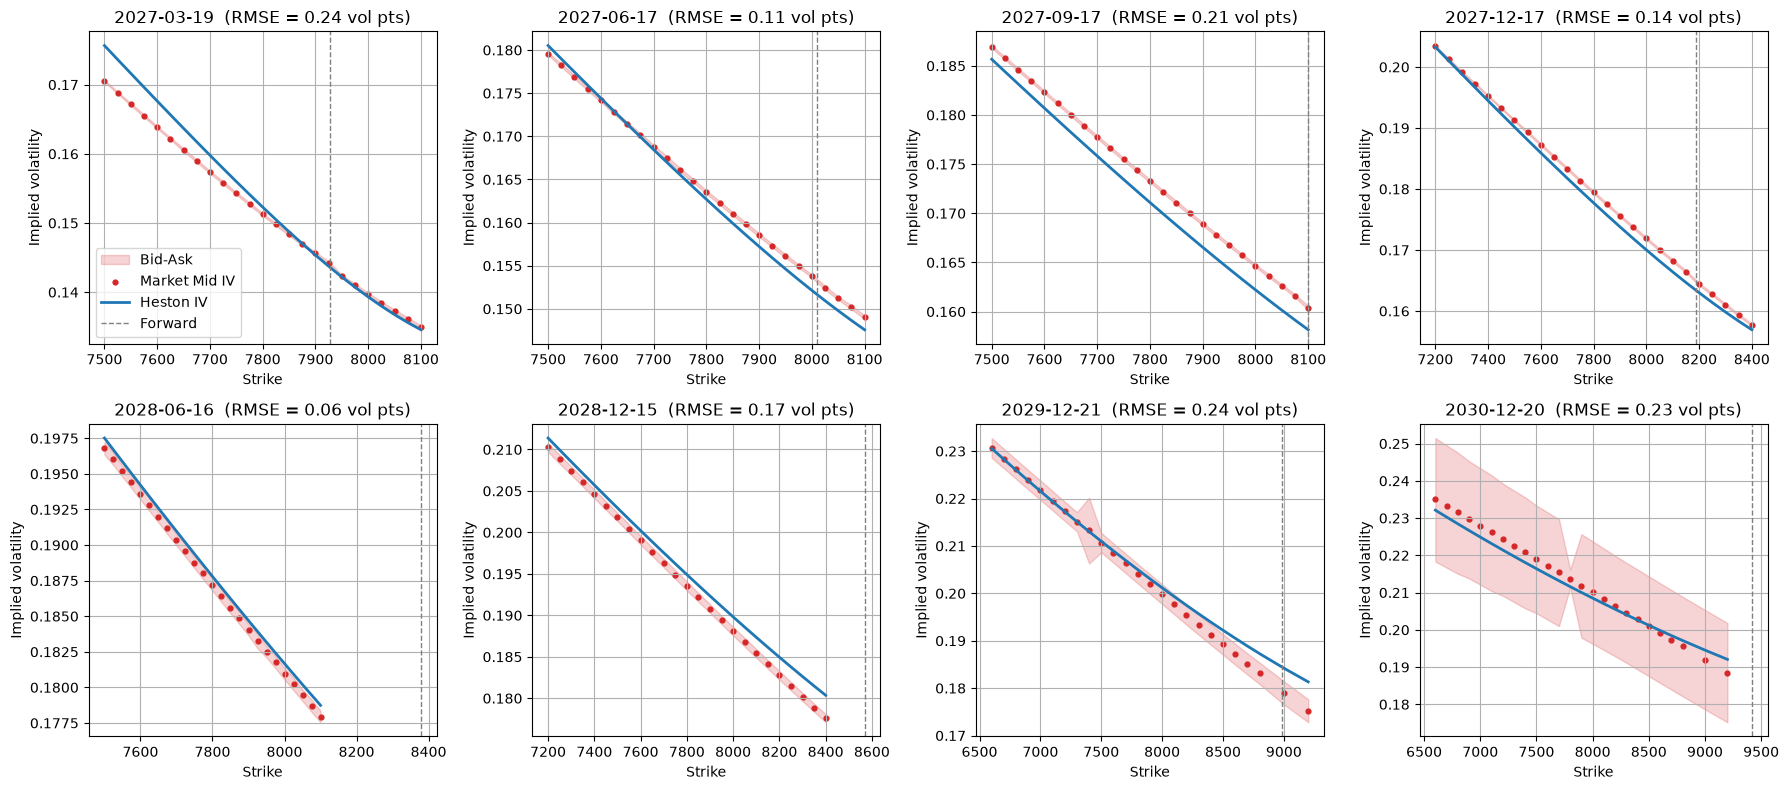

In [31]:
expiry_list = regular_fit_df['Expiry'].unique()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, expiry in enumerate(expiry_list):

    # rows of one expiry
    one_expiry = regular_fit_df[regular_fit_df['Expiry'] == expiry]
    ax = axes[i]

    # market: bid-ask band and mid
    ax.fill_between(one_expiry['Strike'], one_expiry['Bid_iv'], one_expiry['Ask_iv'],
                    color='tab:red', alpha=0.2, label='Bid-Ask')
    
    ax.scatter(one_expiry['Strike'], one_expiry['Mid_iv'],
               color='tab:red', s=12, label='Market Mid IV')

    # Heston: the fitted IV
    ax.plot(one_expiry['Strike'], one_expiry['Heston_iv'],
            color='tab:blue', linewidth=2, label='Heston IV')

    # forward
    forward = one_expiry['F'].iloc[0]
    ax.axvline(forward, color='gray', linestyle='--', linewidth=1, label='Forward')

    # fit error for this expiry, in vol points
    rmse = np.sqrt(((one_expiry['Heston_iv'] - one_expiry['Mid_iv'])**2).mean()) * 100

    ax.set_title(f'{expiry}  (RMSE = {rmse:.2f} vol pts)')
    ax.set_xlabel('Strike')
    ax.set_ylabel('Implied volatility')
    ax.grid(True)

axes[0].legend()       
plt.tight_layout()
plt.show()

In [32]:
rmse, max_abs_error, mean_error = calibration.fit_error_summary(regular_fit_df).values()
print(f'RMSE: {rmse:.4f}\nMaximum Absolute Error: {max_abs_error:.4f}\nMean Error: {mean_error:.4f}')

RMSE: 0.1853
Maximum Absolute Error: 0.6095
Mean Error: -0.0009


## **Weighted Fit**

### **Fitted Parameter**

In [33]:
# initial guess: heston_params from the regular fit section
v_star_2, kappa_star_2, theta_star_2, eta_star_2, rho_star_2, sse_star_2 = calibration.fit_surface_2(
        heston_params, F, K, tau, option, mid_iv, iv_spread)

In [34]:
heston_params_weighted_star = [v_star_2, kappa_star_2, theta_star_2, eta_star_2, rho_star_2]
print(f'v_0: {v_star_2:.4f}\nkappa: {kappa_star_2:.4f}\ntheta: {theta_star_2:.4f}\neta: {eta_star_2:.4f}\nrho: {rho_star_2:.4f}')

v_0: 0.0191
kappa: 4.2030
theta: 0.0481
eta: 1.5952
rho: -0.6037


### **Plot 3D surface**

In [35]:
weighted_fit_df = surface_raw.copy()
weighted_fit_df = calibration.add_heston_iv(weighted_fit_df, heston_params_weighted_star)

In [36]:
# Step 1: Heston IV on a regular (moneyness, tau) grid
moneyness_grid = np.linspace(0.70, 1.05, 30)
tau_grid = np.linspace(weighted_fit_df['tau'].min(), weighted_fit_df['tau'].max(), 25)

heston_iv_grid = np.zeros((len(tau_grid), len(moneyness_grid)))

for i in range(len(tau_grid)):
    for j in range(len(moneyness_grid)):

        tau_ij = tau_grid[i] # slice of ith tau
        k_ij = moneyness_grid[j] # different moneyness on fixed ith tau         

        # out-of-the-money option, same rule as the data
        if k_ij < 1:
            option_ij = 'put'
        else:
            option_ij = 'call'

        price_ij = calibration.heston_price(
            1.0, k_ij, tau_ij, v_star_2, kappa_star_2, theta_star_2, eta_star_2, rho_star_2, option_ij)

        heston_iv_grid[i, j] = calibration.black_implied_vol(
            price_ij, 1.0, k_ij, tau_ij, option_ij)

# Step 2: plot
fig = go.Figure()

# Heston: continuous surface
fig.add_trace(go.Surface(
    x=moneyness_grid, y=tau_grid, z=heston_iv_grid,
    colorscale='Viridis', opacity=0.8, name='Heston IV'))

# Market: discrete dots
fig.add_trace(go.Scatter3d(
    x=weighted_fit_df['Strike'] / weighted_fit_df['F'],
    y=weighted_fit_df['tau'],
    z=weighted_fit_df['Mid_iv'],
    mode='markers', marker=dict(size=3, color='red'),
    name='Market Mid IV'))

# Plot: title
fig.update_layout(
    title='Heston vs Market Implied Volatility Surface',
    width=900, height=700,
    scene=dict(xaxis_title='Moneyness K/F',
               yaxis_title='Time to maturity (years)',
               zaxis_title='Implied volatility'))

fig.show()

### **Error Statistics**

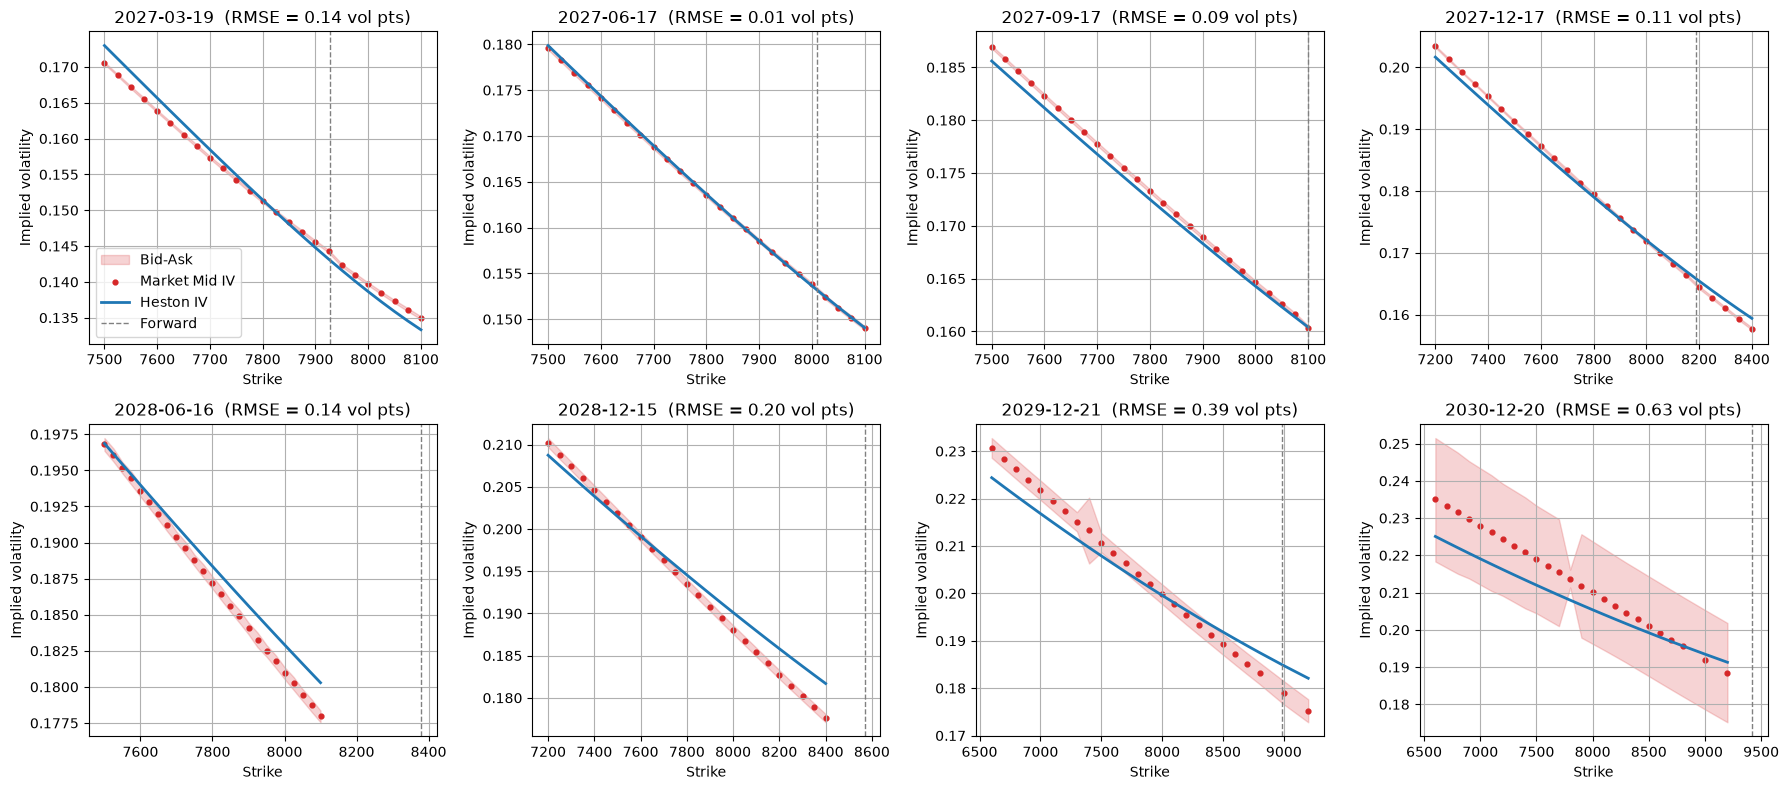

In [37]:
expiry_list = weighted_fit_df['Expiry'].unique()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, expiry in enumerate(expiry_list):

    # rows of one expiry
    one_expiry = weighted_fit_df[weighted_fit_df['Expiry'] == expiry]
    ax = axes[i]

    # market: bid-ask band and mid
    ax.fill_between(one_expiry['Strike'], one_expiry['Bid_iv'], one_expiry['Ask_iv'],
                    color='tab:red', alpha=0.2, label='Bid-Ask')
    
    ax.scatter(one_expiry['Strike'], one_expiry['Mid_iv'],
               color='tab:red', s=12, label='Market Mid IV')

    # Heston: the fitted IV
    ax.plot(one_expiry['Strike'], one_expiry['Heston_iv'],
            color='tab:blue', linewidth=2, label='Heston IV')

    # forward
    forward = one_expiry['F'].iloc[0]
    ax.axvline(forward, color='gray', linestyle='--', linewidth=1, label='Forward')

    # fit error for this expiry, in vol points
    rmse = np.sqrt(((one_expiry['Heston_iv'] - one_expiry['Mid_iv'])**2).mean()) * 100

    ax.set_title(f'{expiry}  (RMSE = {rmse:.2f} vol pts)')
    ax.set_xlabel('Strike')
    ax.set_ylabel('Implied volatility')
    ax.grid(True)

axes[0].legend()       
plt.tight_layout()
plt.show()

In [38]:
rmse, max_abs_error, mean_error = calibration.fit_error_summary(weighted_fit_df).values()
print(f'RMSE: {rmse:.4f}\nMaximum Absolute Error: {max_abs_error:.4f}\nMean Error: {mean_error:.4f}')

RMSE: 0.2829
Maximum Absolute Error: 1.0125
Mean Error: -0.0542


## **Feller Fit**

### **Fitted Parameter**

In [39]:
# initial guess: heston_params from the regular fit section
v_star_3, kappa_star_3, theta_star_3, eta_star_3, rho_star_3, sse_star_3 = calibration.fit_surface_3(
        heston_params, F, K, tau, option, mid_iv, iv_spread)

In [40]:
heston_params_feller_star = [v_star_3, kappa_star_3, theta_star_3, eta_star_3, rho_star_3]
print(f'v_0: {v_star_3:.4f}\nkappa: {kappa_star_3:.4f}\ntheta: {theta_star_3:.4f}\neta: {eta_star_3:.4f}\nrho: {rho_star_3:.4f}')

v_0: 0.0146
kappa: 1.8802
theta: 0.0473
eta: 0.4216
rho: -0.9500


### **Plot 3D surface**

In [41]:
feller_fit_df = surface_raw.copy()
feller_fit_df = calibration.add_heston_iv(feller_fit_df, heston_params_feller_star)

In [42]:
# Step 1: Heston IV on a regular (moneyness, tau) grid
moneyness_grid = np.linspace(0.70, 1.05, 30)
tau_grid = np.linspace(feller_fit_df['tau'].min(), feller_fit_df['tau'].max(), 25)

heston_iv_grid = np.zeros((len(tau_grid), len(moneyness_grid)))

for i in range(len(tau_grid)):
    for j in range(len(moneyness_grid)):

        tau_ij = tau_grid[i] # slice of ith tau
        k_ij = moneyness_grid[j] # different moneyness on fixed ith tau         

        # out-of-the-money option, same rule as the data
        if k_ij < 1:
            option_ij = 'put'
        else:
            option_ij = 'call'

        price_ij = calibration.heston_price(
            1.0, k_ij, tau_ij, v_star_3, kappa_star_3, theta_star_3, eta_star_3, rho_star_3, option_ij)

        heston_iv_grid[i, j] = calibration.black_implied_vol(
            price_ij, 1.0, k_ij, tau_ij, option_ij)

# Step 2: plot
fig = go.Figure()

# Heston: continuous surface
fig.add_trace(go.Surface(
    x=moneyness_grid, y=tau_grid, z=heston_iv_grid,
    colorscale='Viridis', opacity=0.8, name='Heston IV'))

# Market: discrete dots
fig.add_trace(go.Scatter3d(
    x=feller_fit_df['Strike'] / feller_fit_df['F'],
    y=feller_fit_df['tau'],
    z=feller_fit_df['Mid_iv'],
    mode='markers', marker=dict(size=3, color='red'),
    name='Market Mid IV'))

# Plot: title
fig.update_layout(
    title='Heston vs Market Implied Volatility Surface',
    width=900, height=700,
    scene=dict(xaxis_title='Moneyness K/F',
               yaxis_title='Time to maturity (years)',
               zaxis_title='Implied volatility'))

fig.show()

### **Error Statistics**

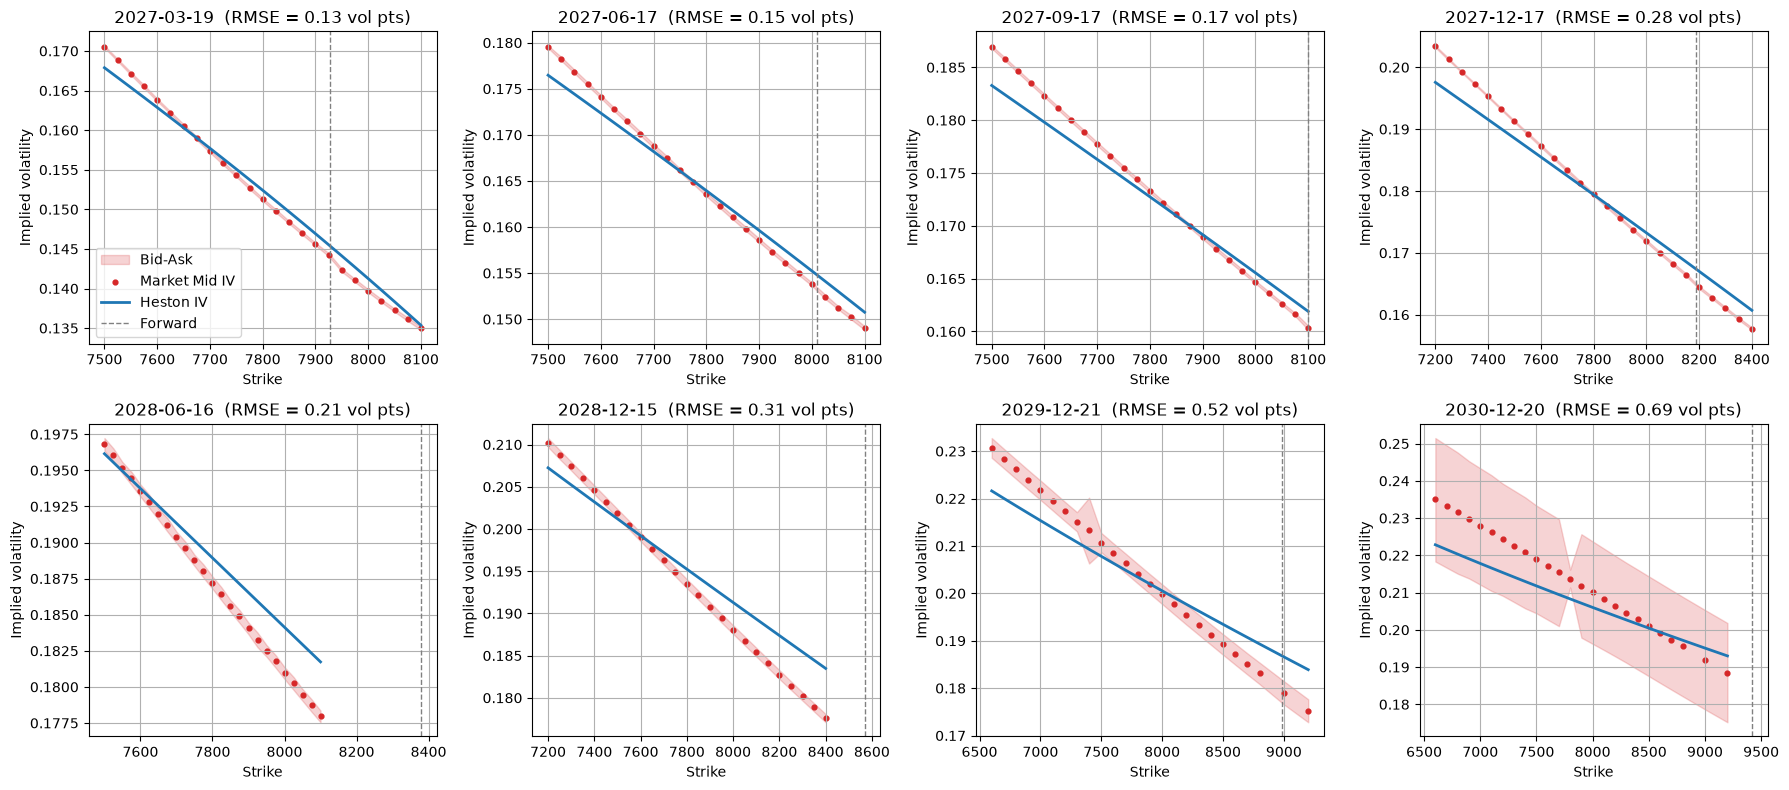

In [43]:
expiry_list = feller_fit_df['Expiry'].unique()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, expiry in enumerate(expiry_list):

    # rows of one expiry
    one_expiry = feller_fit_df[feller_fit_df['Expiry'] == expiry]
    ax = axes[i]

    # market: bid-ask band and mid
    ax.fill_between(one_expiry['Strike'], one_expiry['Bid_iv'], one_expiry['Ask_iv'],
                    color='tab:red', alpha=0.2, label='Bid-Ask')
    
    ax.scatter(one_expiry['Strike'], one_expiry['Mid_iv'],
               color='tab:red', s=12, label='Market Mid IV')

    # Heston: the fitted IV
    ax.plot(one_expiry['Strike'], one_expiry['Heston_iv'],
            color='tab:blue', linewidth=2, label='Heston IV')

    # forward
    forward = one_expiry['F'].iloc[0]
    ax.axvline(forward, color='gray', linestyle='--', linewidth=1, label='Forward')

    # fit error for this expiry, in vol points
    rmse = np.sqrt(((one_expiry['Heston_iv'] - one_expiry['Mid_iv'])**2).mean()) * 100

    ax.set_title(f'{expiry}  (RMSE = {rmse:.2f} vol pts)')
    ax.set_xlabel('Strike')
    ax.set_ylabel('Implied volatility')
    ax.grid(True)

axes[0].legend()       
plt.tight_layout()
plt.show()

In [44]:
rmse, max_abs_error, mean_error = calibration.fit_error_summary(feller_fit_df).values()
print(f'RMSE: {rmse:.4f}\nMaximum Absolute Error: {max_abs_error:.4f}\nMean Error: {mean_error:.4f}')

RMSE: 0.3614
Maximum Absolute Error: 1.2362
Mean Error: -0.0416
